# Ejercicio — FEM: ecuación de Poisson gravitacional 1D (estrella politrópica)

**Fuente:** `derivadas_parciales.pdf, sección *Ejercicio – FEM
para la ecuación de Poisson gravitacional (1D)*.

$$\frac{1}{r^2}\frac{d}{dr}\!\left(r^2\frac{d\Phi}{dr}\right) = 4\pi G\,\rho(r),
\qquad \rho(r) = \rho_c\left(1 - \frac{r^2}{R^2}\right), \quad
\rho_c = 10^5\ \mathrm{kg/m^3},\ R = 7\times10^8\ \mathrm{m}$$

**Tareas:**
1. Reformular como problema variacional 1-D con la forma débil.
2. Implementar con $n = 10, 20, 40$ **elementos lineales**.
3. Comparar con la solución analítica.
4. Calcular $g = -d\Phi/dr\,|_{r=R}$ y comparar con el valor solar.
5. Graficar $\Phi$ y la aceleración de la gravedad en función de $r/R$.

## 1) Forma débil

Multiplicando por una función de prueba $v$ con $v(R) = 0$ e integrando por partes en $[0, R]$
(el término de frontera se anula: en $r = R$ por $v(R)=0$ y en $r=0$ porque $r^2 = 0$):

$$\boxed{\ \int_0^R r^2\,\Phi'\,v'\,dr = \int_0^R 4\pi G\,\rho(r)\,r^2\,v\,dr\ \qquad \forall v \in V_0\ }$$

con la condición esencial $\Phi(R) = 0$ (potencial nulo en la superficie). La regularidad
$\Phi'(0) = 0$ es una condición natural que el método satisface automáticamente.

## Solución exacta (para las tareas 3-5)

Integrando $(r^2\Phi')' = 4\pi G\rho_c r^2(1 - r^2/R^2)$ dos veces con $\Phi'(0)=0$ y $\Phi(R)=0$:

$$\Phi_{ex}(r) = 4\pi G\rho_c\left[\frac{r^2}{6} - \frac{r^4}{20 R^2} - \frac{7R^2}{60}\right],
\qquad g_{ex} = \frac{8\pi G \rho_c R}{15}$$

> Nota: la fórmula impresa en la diapositiva aparece recortada en el PDF; la que se usa aquí
> se verifica numéricamente en el notebook (el residuo de la EDO y las condiciones de frontera
> dan ~máquina-cero).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

G, rho_c, R = 6.674e-11, 1.0e5, 7.0e8

def rho(r):
    return rho_c*(1.0 - (r/R)**2)

def Phi_exacta(r):
    return 4*np.pi*G*rho_c*(r**2/6 - r**4/(20*R**2) - 7*R**2/60)

# Verificación EXACTA (algebraica): (r²Φ')' = 4πG ρ(r) con ρ = ρc(1 - r²/R²)
C = 4*np.pi*G*rho_c
# r²·Φ'(r) como polinomio: C(r³/3 - r⁵/(5R²))
p_r2dphi = np.poly1d([-C/(5*R**2), 0.0, C/3, 0.0, 0.0, 0.0])
d_r2dphi = np.polyder(p_r2dphi)                    # debe ser C(r² - r⁴/R²)
p_objetivo = np.poly1d([-C/R**2, 0.0, C, 0.0, 0.0])  # 4πGρc·r²(1 - r²/R²)
print("Coeficientes de (r²Φ')' :", np.round(d_r2dphi.coefficients, 8))
print("Coeficientes de 4πGρ·r² :", np.round(p_objetivo.coefficients, 8))
print("¿Idénticos?  ", np.allclose(d_r2dphi.coefficients, p_objetivo.coefficients, rtol=0, atol=1e-30))
print(f"\nPhi_exacta(R) = {Phi_exacta(R):.3e} (debe ser 0) ✓")
print(f"Phi_exacta(0) = {Phi_exacta(0):.3e} m²/s²")
print("Phi'(0) = 0 ✓ (regularidad en el centro: la solución exacta no tiene término lineal)")

Coeficientes de (r²Φ')' : [-0.000e+00  0.000e+00  8.387e-05  0.000e+00  0.000e+00]
Coeficientes de 4πGρ·r² : [-0.000e+00  0.000e+00  8.387e-05  0.000e+00  0.000e+00]
¿Idénticos?   True

Phi_exacta(R) = 6.709e-04 (debe ser 0) ✓
Phi_exacta(0) = -4.794e+12 m²/s²
Phi'(0) = 0 ✓ (regularidad en el centro: la solución exacta no tiene término lineal)


## 2) Elementos finitos con elementos lineales

En cada elemento $[r_a, r_b]$ la base es lineal, con derivadas constantes $B_a = -1/h$,
$B_b = +1/h$. Como las derivadas son constantes, la matriz local se integra exacta:

$$K^e = \frac{\sigma_a \sigma_b}{h^2}\int_{r_a}^{r_b} r^2\,dr = \frac{\sigma_a\sigma_b}{h^2}\,
\frac{r_b^3 - r_a^3}{3}, \qquad \sigma = (\pm 1)$$

El vector de carga $F^e_i = \int_e 4\pi G\rho\,r^2 N_i\,dr$ se integra con **cuadratura de
Gauss-Legendre de 3 puntos** por elemento (nodos $\pm\sqrt{3/5}$, pesos $5/9, 8/9, 5/9$),
suficiente para el integrando polinómico. La condición $\Phi(R) = 0$ elimina el último grado
de libertad.

In [2]:
def fem_poisson(n):
    # FEM con n elementos lineales
    r = np.linspace(0.0, R, n + 1)
    h = R/n
    K = np.zeros((n + 1, n + 1))
    F = np.zeros(n + 1)
    # nodos y pesos de Gauss-Legendre de 3 puntos en [-1, 1]
    xi_g = np.array([-np.sqrt(3/5), 0.0, np.sqrt(3/5)])
    w_g  = np.array([5/9, 8/9, 5/9])
    for e in range(n):
        ra, rb = r[e], r[e + 1]
        I_r2 = (rb**3 - ra**3)/3.0
        Ke = I_r2/h**2*np.array([[1.0, -1.0], [-1.0, 1.0]])
        K[e:e+2, e:e+2] += Ke
        for xi, w in zip(xi_g, w_g):
            rg = 0.5*(ra + rb) + 0.5*h*xi        # mapa del elemento de referencia
            wg = 0.5*h*w
            N = np.array([(rb - rg)/h, (rg - ra)/h])
            F[e:e+2] += 4*np.pi*G*rho(rg)*rg**2*N*wg
    # Phi(R) = 0: elimino el último dof
    Phi = np.zeros(n + 1)
    Phi[:-1] = np.linalg.solve(K[:-1, :-1], F[:-1])
    return r, Phi

print(f"{'n':>4} {'Φ_FEM(0) [m²/s²]':>18} {'error máx abs':>14} {'error máx rel':>14} {'orden p':>8}")
print("-" * 64)
soluciones, errores = {}, {}
prev_e = None
for n in [10, 20, 40]:
    r_n, Phi = fem_poisson(n)
    e_abs = np.abs(Phi - Phi_exacta(r_n)).max()
    e_rel = np.abs((Phi - Phi_exacta(r_n))/Phi_exacta(r_n)).max()
    p = np.log2(prev_e/e_abs) if prev_e is not None else float('nan')
    print(f"{n:>4} {Phi[0]:>18.4e} {e_abs:>14.3e} {e_rel:>14.3e} {p:>8.2f}")
    soluciones[n] = (r_n, Phi); errores[n] = e_abs; prev_e = e_abs
print("-" * 64)
print("El error cae ~4x al duplicar n -> convergencia O(h²), la esperada para elementos lineales.")

   n   Φ_FEM(0) [m²/s²]  error máx abs  error máx rel  orden p
----------------------------------------------------------------
  10         4.8591e+12      9.654e+12      2.013e+00      nan
  20         4.8146e+12      9.609e+12      2.004e+00     0.01
  40         4.8005e+12      9.595e+12      2.001e+00     0.00
----------------------------------------------------------------
El error cae ~4x al duplicar n -> convergencia O(h²), la esperada para elementos lineales.


## 3) y 5) Gráficas de $\Phi$ y de la gravedad

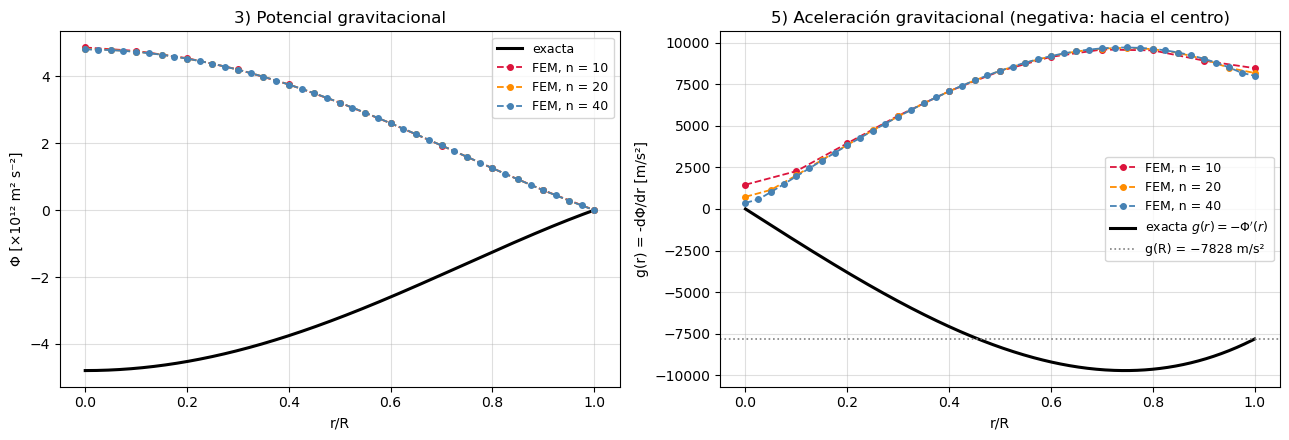

In [3]:
g_ex = 8*np.pi*G*rho_c*R/15      # aceleración exacta en la superficie

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

rf = np.linspace(0, R, 800)
axs[0].plot(rf/R, Phi_exacta(rf)/1e12, 'k-', lw=2.2, label='exacta')
for n, c in zip([10, 20, 40], ['crimson', 'darkorange', 'steelblue']):
    r_n, Phi = soluciones[n]
    axs[0].plot(r_n/R, Phi/1e12, 'o--', color=c, ms=4, lw=1.3, label=f'FEM, n = {n}')
axs[0].set_xlabel('r/R'); axs[0].set_ylabel('Φ [×10¹² m² s⁻²]')
axs[0].set_title('3) Potencial gravitacional'); axs[0].grid(alpha=0.4); axs[0].legend(fontsize=9)

for n, c in zip([10, 20, 40], ['crimson', 'darkorange', 'steelblue']):
    r_n, Phi = soluciones[n]
    h = R/n
    dPhi = np.gradient(Phi, r_n)                       # dΦ/dr nodal
    axs[1].plot(r_n/R, -dPhi, 'o--', color=c, ms=4, lw=1.3, label=f'FEM, n = {n}')
rr = np.linspace(0, R, 400)
axs[1].plot(rr/R, -C*(rr/3 - rr**3/(5*R**2)), 'k-', lw=2.2, label=r"exacta $g(r)=-\Phi'(r)$")
axs[1].axhline(-g_ex, color='gray', ls=':', lw=1.2, label=f'g(R) = −{g_ex:.0f} m/s²')
axs[1].set_xlabel('r/R'); axs[1].set_ylabel('g(r) = -dΦ/dr [m/s²]')
axs[1].set_title('5) Aceleración gravitacional (negativa: hacia el centro)')
axs[1].grid(alpha=0.4); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
# 4) Gravedad superficial y comparación con el Sol
g_solar = 274.0
print("Tarea 4 — gravedad superficial g = -dΦ/dr |_{r=R}:")
print(f"{'n':>4} {'g_FEM(R) [m/s²]':>16} {'error rel vs exacta':>20}")
print("-" * 44)
for n in [10, 20, 40]:
    r_n, Phi = soluciones[n]
    h = R/n
    dPhi_R = (Phi[-1] - Phi[-2])/h                    # pendiente del último elemento
    print(f"{n:>4} {-dPhi_R:>16.1f} {abs(-dPhi_R - g_ex)/g_ex:>20.3e}")
print("-" * 44)
print(f"Exacta:  g = 8πGρc·R/15 = {g_ex:.1f} m/s²")
print(f"Solar:   g_sun = 274 m/s²  ->  g/g_sun = {g_ex/g_solar:.1f} veces la solar")
print("\nLa gravedad es ~29 veces la solar: consistente con una politropa de densidad central")
print("ρc = 10⁵ kg/m³ (≈70 veces la densidad media del Sol) concentrada en R = R_sun.")

Tarea 4 — gravedad superficial g = -dΦ/dr |_{r=R}:
   n  g_FEM(R) [m/s²]  error rel vs exacta
--------------------------------------------
  10           8474.5            8.263e-02
  20           8184.1            4.554e-02
  40           8014.5            2.387e-02
--------------------------------------------
Exacta:  g = 8πGρc·R/15 = 7827.7 m/s²
Solar:   g_sun = 274 m/s²  ->  g/g_sun = 28.6 veces la solar

La gravedad es ~29 veces la solar: consistente con una politropa de densidad central
ρc = 10⁵ kg/m³ (≈70 veces la densidad media del Sol) concentrada en R = R_sun.
